# 16 枚方のαA推定モデル

240924_枚方_αA収束計算の14節点・20流路・ファン値を保持。5つの未知開口は元の初期値0.01 m²。

## 到達目標
目標風量は69.4、122.9、115.5、21.8、77.4 m³/h。目的関数はそれらと計算風量の差のノルム。今回は初期値モデルを検証し、最適化結果の再現は未検証。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/16/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "16"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'16_hirakata_alphaA': {'builder': {},
                        'simulation': {'index': {'start': '2021-01-01T00:00:00',
                                                 'end': '2021-01-01T00:00:01',
                                                 'length': 2,
                                                 'timestep': 1}},
                        'nodes': [{'key': '外部',
                                   'calc_p': False,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '1F_HEX',
                                   'calc_p': False,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '2F_HEX',
                                   'calc_p': False,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '1F_吸込',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '2F_吸込',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': 'LDK',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '和室',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '1Fホール',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '脱衣所',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '寝室',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': 'ロフト',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '洋室',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '廊下',
                                   'calc_p': True,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False},
                                  {'key': '床下',
                                   'calc_p': False,
                                   'calc_t': False,
                                   'calc_x': False,
                                   'calc_c': False}],
                        'ventilation_branches': [{'key': 'LDK->1F_吸込',
                                                  'source': 'LDK',
                                                  'target': '1F_吸込',
                                                  'type': 'fan',
                                                  'p_max': 290,
                                                  'q_max': 0.0855,
                                                  'p1': 200,
                                                  'q1': 0.0855},
                                                 {'key': '1F_吸込->和室',
                                                  'source': '1F_吸込',
                                                  'target': '和室',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '1F_吸込->1Fホール',
                                                  'source': '1F_吸込',
                                                  'target': '1Fホール',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '1F_吸込->脱衣所',
                                                  'source': '1F_吸込',
                                                  'target': '脱衣所',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '脱衣所->1F_HEX',
                                                  'source': '脱衣所',
                                                  'target': '1F_HEX',
                                                  'type': 'fan',
                                                  'p_max': 200,
                                                  'q_max': 0.027555555555555555,
                                                  'p1': 100,
                                                  'q1': 0.027555555555555555},
                                                 {'key': '1F_HEX->和室',
                                                  'source': '1F_HEX',
                                                  'target': '和室',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '1F_HEX->LDK',
                                                  'source': '1F_HEX',
                                                  'target': 'LDK',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '和室->LDK',
                                                  'source': '和室',
                                                  'target': 'LDK',
                                                  'type': 'gap',
                                                  'a': 0.05555555555555555,
                                                  'n': 2.5},
                                                 {'key': '1Fホール->LDK',
                                                  'source': '1Fホール',
                                                  'target': 'LDK',
                                                  'type': 'gap',
                                                  'a': 0.027777777777777776,
                                                  'n': 2.5},
                                                 {'key': '脱衣所->LDK',
                                                  'source': '脱衣所',
                                                  'target': 'LDK',
                                                  'type': 'gap',
                                                  'a': 0.027777777777777776,
                                                  'n': 2.5},
                                                 {'key': '廊下->2F_吸込',
                                                  'source': '廊下',
                                                  'target': '2F_吸込',
                                                  'type': 'fan',
                                                  'p_max': 290,
                                                  'q_max': 0.08333333333333333,
                                                  'p1': 200,
                                                  'q1': 0.08333333333333333},
                                                 {'key': '2F_吸込->洋室',
                                                  'source': '2F_吸込',
                                                  'target': '洋室',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.02},
                                                 {'key': '2F_吸込->寝室',
                                                  'source': '2F_吸込',
                                                  'target': '寝室',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.15},
                                                 {'key': '2F_吸込->ロフト',
                                                  'source': '2F_吸込',
                                                  'target': 'ロフト',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '廊下->2F_HEX',
                                                  'source': '廊下',
                                                  'target': '2F_HEX',
                                                  'type': 'fan',
                                                  'p_max': 200,
                                                  'q_max': 0.025,
                                                  'p1': 100,
                                                  'q1': 0.025},
                                                 {'key': '2F_HEX->洋室',
                                                  'source': '2F_HEX',
                                                  'target': '洋室',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.01},
                                                 {'key': '2F_HEX->寝室',
                                                  'source': '2F_HEX',
                                                  'target': '寝室',
                                                  'type': 'simple_opening',
                                                  'alpha': 1.0,
                                                  'area': 0.1},
                                                 {'key': '洋室->廊下',
                                                  'source': '洋室',
                                                  'target': '廊下',
                                                  'type': 'gap',
                                                  'a': 0.05555555555555555,
                                                  'n': 2.5},
                                                 {'key': '寝室->廊下',
                                                  'source': '寝室',
                                                  'target': '廊下',
                                                  'type': 'gap',
                                                  'a': 0.027777777777777776,
                                                  'n': 2.5},
                                                 {'key': 'ロフト->廊下',
                                                  'source': 'ロフト',
                                                  'target': '廊下',
                                                  'type': 'simple_opening',
                                                  'alpha': 0.65,
                                                  'area': 2.0}],
                        'thermal_branches': []}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


16_hirakata_alphaA artifacts.1794699690649.output.ae69cdf50a8c4f54b0c98876c1ee5c72


,目標風量,初期開口での計算風量,差
1F_吸込->和室,69.4,102.723328,33.323328
1F_吸込->1Fホール,122.9,97.593544,-25.306456
1F_吸込->脱衣所,115.5,107.483124,-8.016876
1F_HEX->和室,21.8,44.535458,22.735458
1F_HEX->LDK,77.4,54.664539,-22.735461


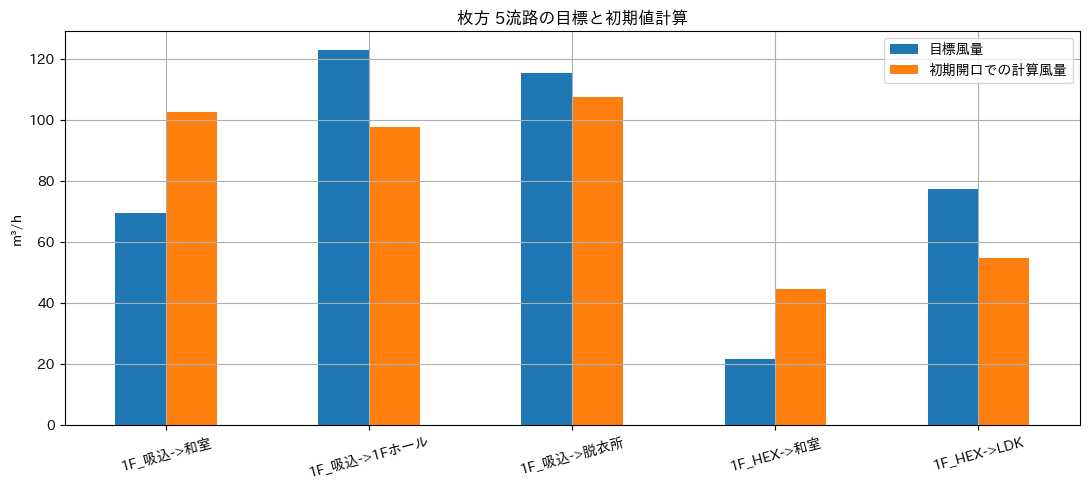

In [5]:
frames = {name: result.get_series_df("vent_flow_rate", raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    frame.to_csv(OUTPUT / (name + "_vent_flow_rate.csv"), encoding="utf-8-sig")
    targets = pd.Series({"1F_吸込->和室":69.4, "1F_吸込->1Fホール":122.9,
                         "1F_吸込->脱衣所":115.5, "1F_HEX->和室":21.8, "1F_HEX->LDK":77.4})
    observed = frame.iloc[-1].reindex(targets.index) * 3600
    assert np.isfinite(observed).all()
    comparison = pd.DataFrame({"目標風量":targets, "初期開口での計算風量":observed})
    comparison["差"] = comparison["初期開口での計算風量"] - comparison["目標風量"]
    display(comparison)
    comparison.to_csv(OUTPUT / "initial_target_comparison.csv",encoding="utf-8-sig")
    ax = comparison[["目標風量","初期開口での計算風量"]].plot.bar(
        figsize=(11,5),rot=15,grid=True,ylabel="m³/h",title="枚方 5流路の目標と初期値計算")
    ax.figure.tight_layout()
    ax.figure.savefig(OUTPUT / "initial_target_comparison.png",dpi=140,bbox_inches="tight")
    plt.show()


## 確認・発展
まず感度を確認し、探索の下限0.001／上限5.0 m²が物理的に妥当か見直す。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S070 240924_枚方_αA収束計算.ipynb
- S071 240925_枚方_αA収束計算.ipynb 

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。